# Plotting KDEs and Ridgelines with matplotlib

## Note regarding Google Colab

If we need a package installed in Google Colab, we can do it with:

```
!pip install pandas
```

Or if we want to use the `uv` setup:
```
!pip install uv
!wget https://raw.githubusercontent.com/bersavosh/S3011/refs/heads/main/pyproject.toml
!uv pip install -r pyproject.toml

We are going to use [KDEpy](https://kdepy.readthedocs.io/en/latest/index.html) for KDE plotting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from KDEpy import FFTKDE
import cmasher as cm

from matplotlib import rc
rc('font',**{'family':'sans-serif','sans-serif':['Helvetica']})
rc('text', usetex=False)
rc('font', family='serif')

DATA_DIR = 'https://raw.githubusercontent.com/bersavosh/S3011/main/data/'

We will work with a data based on a study of perception of probability:

Each row represents a response to the question: "*What probability percentage would you assign to the phrase [...]?*"

The study was done by CIA on perception of probabilistic phrases. For more information, see the following references:
- [Critical Thinking For Strategic Intelligence](https://books.google.com.au/books?id=_X0FHYpHDzoC)
- [Github repository by Zonination](https://github.com/zonination/perceptions)
- [Recreation by Yan Holtz on Data2Viz](https://www.data-to-viz.com/story/OneNumOneCatSeveralObs.html)

In [2]:
data = pd.read_csv(DATA_DIR+'perception_of_probability.csv')
data.head()

,Almost Certainly,Highly Likely,Very Good Chance,Probable,Likely,Probably,We Believe,Better Than Even,About Even,We Doubt,Improbable,Unlikely,Probably Not,Little Chance,Almost No Chance,Highly Unlikely,Chances Are Slight
0,95.0,80,85,75,66,75,66,55.0,50,40,20.0,30,15.0,20,5.0,25,25
1,95.0,75,75,51,75,51,51,51.0,50,20,49.0,25,49.0,5,5.0,10,5
2,95.0,85,85,70,75,70,80,60.0,50,30,10.0,25,25.0,20,1.0,5,15
3,95.0,85,85,70,75,70,80,60.0,50,30,10.0,25,25.0,20,1.0,5,15
4,98.0,95,80,70,70,75,65,60.0,50,10,50.0,5,20.0,5,1.0,2,10


## Method I - basic and flexible
- Extenral KDE estimator
- Basic matplotlib

This allows using our own KDE method, but requires us to do most parts manually.
This is suitable when dataset is large, or very specialized/customized visualization is needed.

In [3]:
certainly = data['Almost Certainly'].values
kde_certainly = FFTKDE(kernel='gaussian', bw='silverman').fit(certainly).evaluate()

even = data['About Even'].values
kde_even = FFTKDE(kernel='gaussian', bw='silverman').fit(even).evaluate()

nochance = data['Almost No Chance'].values
kde_nochance = FFTKDE(kernel='gaussian', bw='silverman').fit(nochance).evaluate()

/home/arash/Dropbox/DataViz_2026/S3011_repo/.venv/lib/python3.14/site-packages/KDEpy/bw_selection.py:285: UserWarning: Silverman's rule failed. Too many idential values. Setting bw = 1.0321341385332972
  warnings.warn(


Note the failure of the silverman method above, which forced the algorithm to choose a different bandwidth.

Now onto plotting:

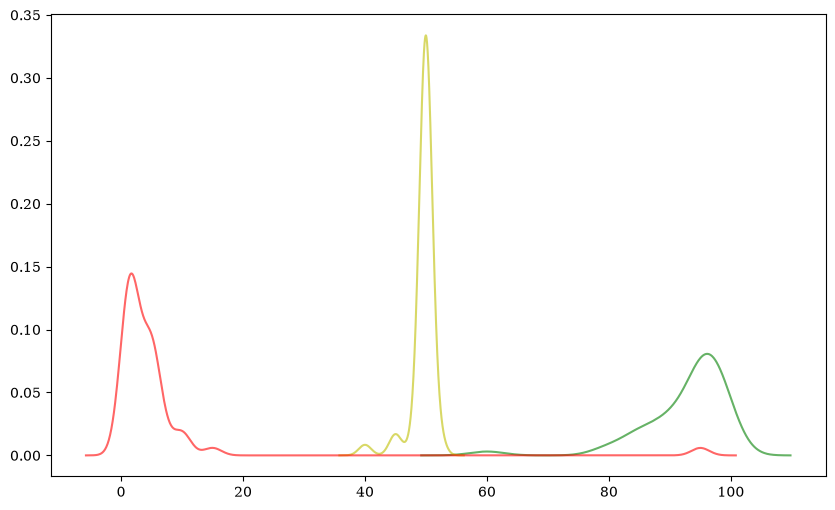

In [4]:
fig = plt.figure(figsize=(10,6))
ax = fig.add_subplot(1,1,1)

ax.plot(kde_certainly[0],kde_certainly[1],color='g',alpha=0.6,label='Almost Certainly')
ax.plot(kde_even[0],kde_even[1],color='y',alpha=0.6,label='About Even')
ax.plot(kde_nochance[0],kde_nochance[1],color='r',alpha=0.6,label='Almost No Chance')

We can improve the aesthetics now:

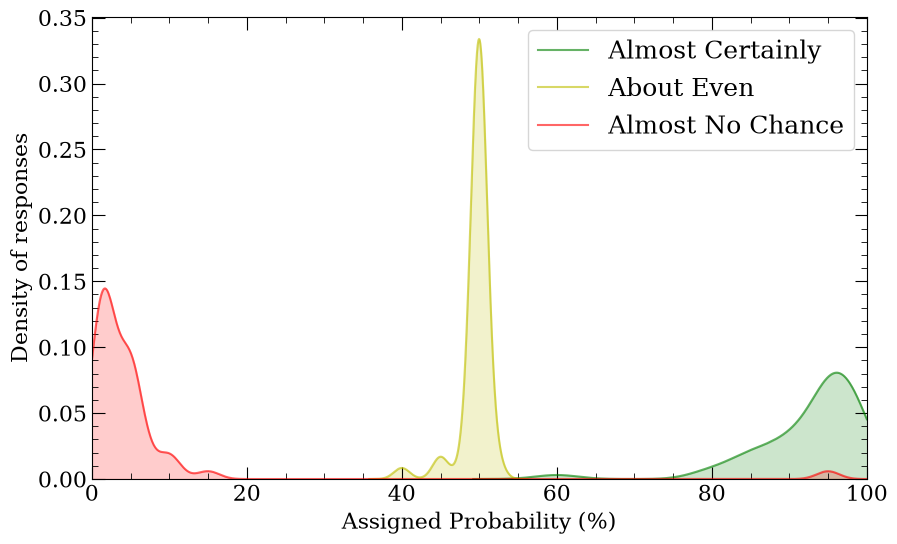

In [5]:
fig = plt.figure(figsize=(10,6))
ax = fig.add_subplot(1,1,1)

ax.plot(kde_certainly[0],kde_certainly[1],color='g',alpha=0.6,label='Almost Certainly')
ax.plot(kde_even[0],kde_even[1],color='y',alpha=0.6,label='About Even')
ax.plot(kde_nochance[0],kde_nochance[1],color='r',alpha=0.6,label='Almost No Chance')

ax.fill_between(kde_certainly[0],kde_certainly[1],color='g',alpha=0.2)
ax.fill_between(kde_even[0],kde_even[1],color='y',alpha=0.2)
ax.fill_between(kde_nochance[0],kde_nochance[1],color='r',alpha=0.2)

ax.legend(fontsize=18)
ax.set_xlabel('Assigned Probability (%)',fontsize=16)
ax.set_ylabel('Density of responses',fontsize=16)

ax.set_xlim(0,100)
ax.set_ylim(0)
ax.minorticks_on()
ax.tick_params(axis='both', which='major', labelsize=16)
ax.tick_params(axis='both', which='major', length=9)
ax.tick_params(axis='both', which='minor', length=4.5)
ax.tick_params(axis='both', which='both',direction='in',right=True,top=True)

## Method II - Pandas functions

Pandas has a set of quick plotting functions relying on matplotlib, we can exploit them to make our plots faster.

In the case of KDEs, note that the Pandas implementation (like many other packages) relies on `scipy` for estimation.

<Axes: ylabel='Density'>

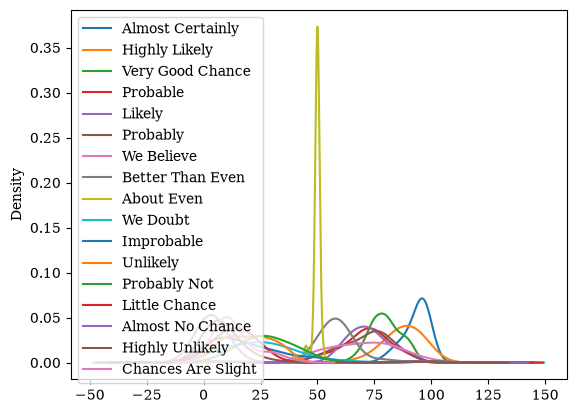

In [6]:
data.plot.kde(bw_method='silverman')

<Axes: ylabel='Density'>

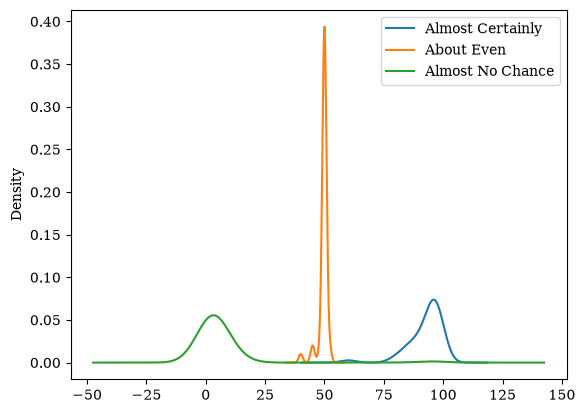

In [7]:
dataslice = data[['Almost Certainly','About Even','Almost No Chance']]
dataslice.plot.kde()

Alright, so this function, returns a matplotlib `axes`. We can exploit this to tweat this function as we like:

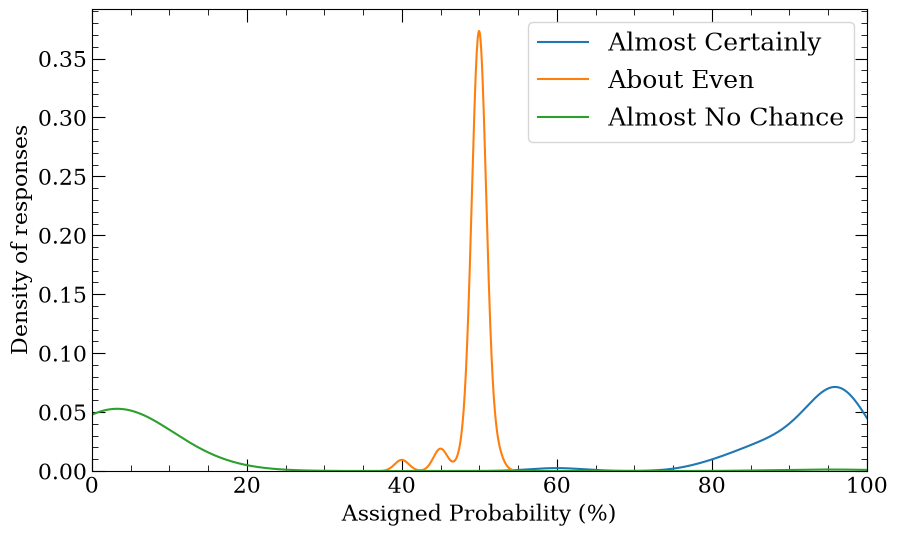

In [8]:
fig = plt.figure(figsize=(10,6))
ax = fig.add_subplot(1,1,1)
dataslice.plot.kde(bw_method='silverman',ax=ax)

ax.legend(fontsize=18)
ax.set_xlabel('Assigned Probability (%)',fontsize=16)
ax.set_ylabel('Density of responses',fontsize=16)

ax.set_xlim(0,100)
ax.set_ylim(0)
ax.minorticks_on()
ax.tick_params(axis='both', which='major', labelsize=16)
ax.tick_params(axis='both', which='major', length=9)
ax.tick_params(axis='both', which='minor', length=4.5)
ax.tick_params(axis='both', which='both',direction='in',right=True,top=True)

## Ridgeline

As we saw above, the KDE plot for all the columns makes it difficult to interpret. 

In these cases, a ridgeline plot is helpful. We follow the matplotlib example [here](https://matplotlib.org/matplotblog/posts/create-ridgeplots-in-matplotlib/).

Note that there are bundled and declarative ways to make ridgeline plots in python. However, this example gives us a good excuse to do something a bit more complex in matplotlib to learn how more sophisticated plots can be made.

First let's get our data ready:

In [9]:
phrases = data.columns.values
phrases

<StringArray>
[  'Almost Certainly',      'Highly Likely',   'Very Good Chance',
           'Probable',             'Likely',           'Probably',
         'We Believe',   'Better Than Even',         'About Even',
           'We Doubt',         'Improbable',           'Unlikely',
       'Probably Not',      'Little Chance',   'Almost No Chance',
    'Highly Unlikely', 'Chances Are Slight']
Length: 17, dtype: str

And we choose a set of colors for our ridgeline:

In [10]:
colors = cm.take_cmap_colors(cm.chroma,len(phrases)+2)
colors

[(np.float64(0.0), np.float64(0.0), np.float64(0.0)),
 (np.float64(0.00573154), np.float64(0.02912873), np.float64(0.08432983)),
 (np.float64(0.01954042), np.float64(0.06589623), np.float64(0.2666522)),
 (np.float64(0.16272937), np.float64(0.01477506), np.float64(0.43515623)),
 (np.float64(0.29332284), np.float64(0.0058223), np.float64(0.46150768)),
 (np.float64(0.40528109), np.float64(0.0082214), np.float64(0.44471904)),
 (np.float64(0.51556955), np.float64(0.00168532), np.float64(0.39742009)),
 (np.float64(0.61651033), np.float64(0.03096663), np.float64(0.31511231)),
 (np.float64(0.69098506), np.float64(0.13898395), np.float64(0.21416554)),
 (np.float64(0.73065519), np.float64(0.26801228), np.float64(0.11927466)),
 (np.float64(0.73744739), np.float64(0.38526723), np.float64(0.04023277)),
 (np.float64(0.71832881), np.float64(0.49927709), np.float64(0.00121957)),
 (np.float64(0.66985104), np.float64(0.61166609), np.float64(0.06507801)),
 (np.float64(0.57764488), np.float64(0.72440045),

### Step 1: the basics of multiple subplots

/home/arash/Dropbox/DataViz_2026/S3011_repo/.venv/lib/python3.14/site-packages/KDEpy/bw_selection.py:285: UserWarning: Silverman's rule failed. Too many idential values. Setting bw = 1.0321341385332972
  warnings.warn(


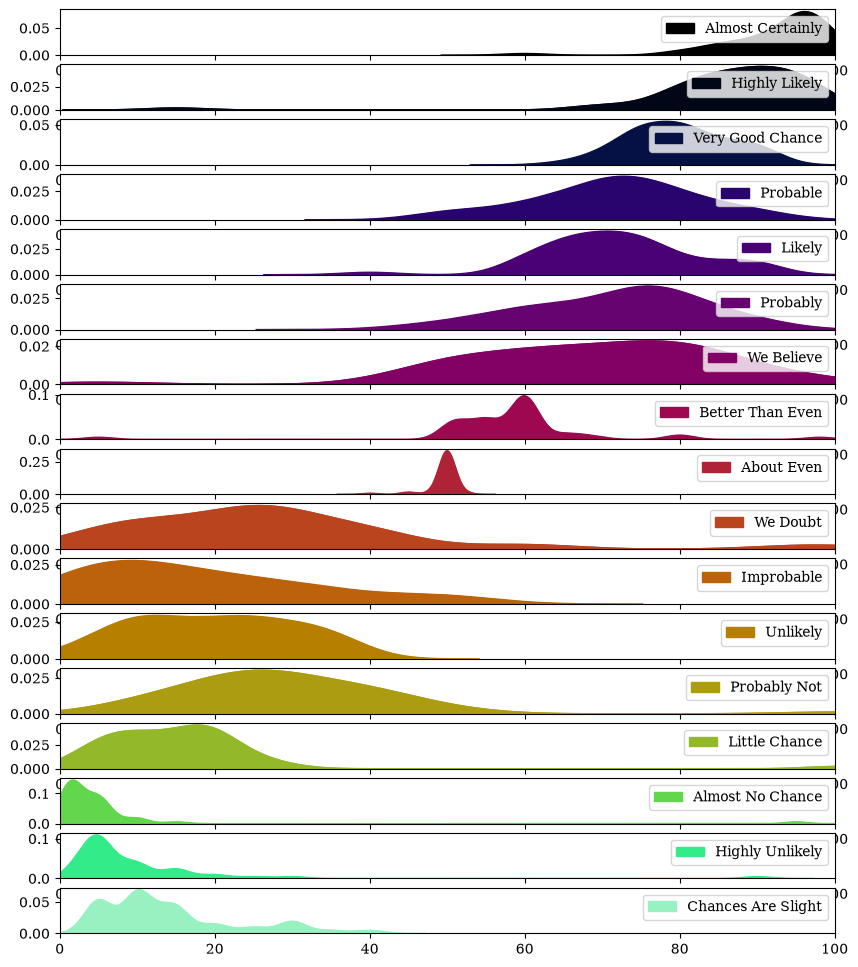

In [11]:
gs = (gridspec.GridSpec(len(phrases),1))
fig = plt.figure(figsize=(10,12))

i = 0

#creating empty list
ax_objs = []

for phrase in phrases:
    # creating new axes object and appending to ax_objs
    ax_objs.append(fig.add_subplot(gs[i:i+1, 0:]))

    # Estimating the KDE
    counts = data[phrase].values
    kde_counts_x, kde_counts_y = FFTKDE(kernel='gaussian', bw='silverman').fit(counts).evaluate()


    # plotting
    ax_objs[-1].plot(kde_counts_x, kde_counts_y, color=colors[i],lw=1)
    ax_objs[-1].fill_between(kde_counts_x, kde_counts_y,color=colors[i],label=phrase)

    # Aesthetics
    ax_objs[-1].legend(loc=1)
    ax_objs[-1].set_xlim(0,100)
    ax_objs[-1].set_ylim(0)

    # Going to the next axes
    i += 1


### Step 2: making overlapping axes with `GridSpec.update()`

/home/arash/Dropbox/DataViz_2026/S3011_repo/.venv/lib/python3.14/site-packages/KDEpy/bw_selection.py:285: UserWarning: Silverman's rule failed. Too many idential values. Setting bw = 1.0321341385332972
  warnings.warn(


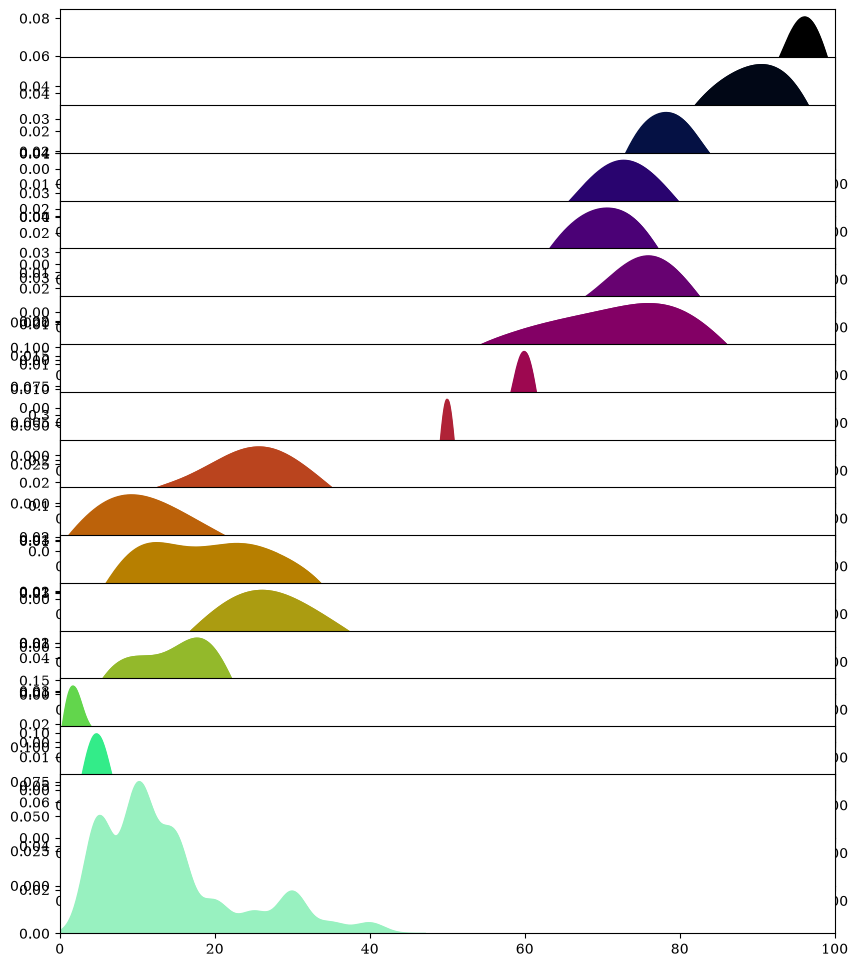

In [12]:
phrases = data.columns.values

gs = (gridspec.GridSpec(len(phrases),1))

fig = plt.figure(figsize=(10,12))

i = 0

#creating empty list
ax_objs = []

for phrase in phrases:
    # creating new axes object and appending to ax_objs
    ax_objs.append(fig.add_subplot(gs[i:i+1, 0:]))

    # Estimating the KDE
    counts = data[phrase].values
    kde_counts_x, kde_counts_y = FFTKDE(kernel='gaussian', bw='silverman').fit(counts).evaluate()


    # plotting
    ax_objs[-1].plot(kde_counts_x, kde_counts_y, color=colors[i],lw=1)
    ax_objs[-1].fill_between(kde_counts_x, kde_counts_y,color=colors[i],label=phrase)

    # Aesthetics
    ax_objs[-1].set_xlim(0,100)
    ax_objs[-1].set_ylim(0)

    # Going to the next axes
    i += 1

# Reducing the horizontal space between axes (negative value makes them overlap)
gs.update(hspace=-0.7)

### Step 3: de-spining axes

/home/arash/Dropbox/DataViz_2026/S3011_repo/.venv/lib/python3.14/site-packages/KDEpy/bw_selection.py:285: UserWarning: Silverman's rule failed. Too many idential values. Setting bw = 1.0321341385332972
  warnings.warn(


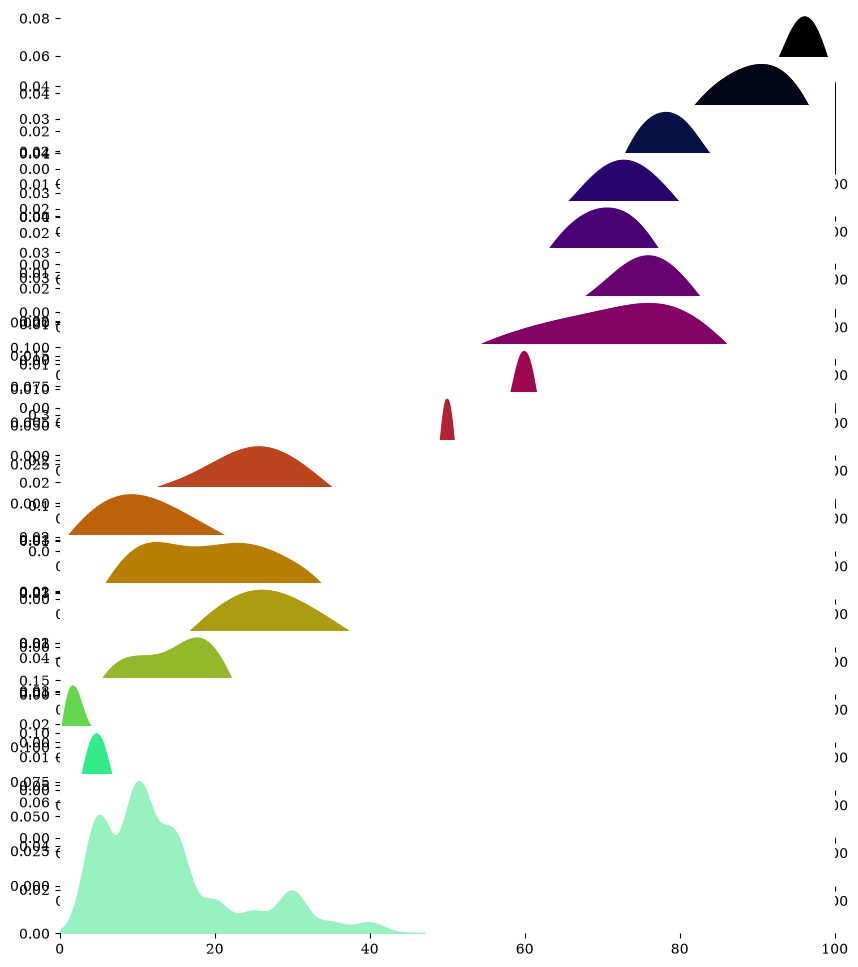

In [13]:
phrases = data.columns.values

gs = (gridspec.GridSpec(len(phrases),1))

fig = plt.figure(figsize=(10,12))

i = 0

#creating empty list
ax_objs = []

for phrase in phrases:
    # creating new axes object and appending to ax_objs
    ax_objs.append(fig.add_subplot(gs[i:i+1, 0:]))

    # Estimating the KDE
    counts = data[phrase].values
    kde_counts_x, kde_counts_y = FFTKDE(kernel='gaussian', bw='silverman').fit(counts).evaluate()


    # plotting
    ax_objs[-1].plot(kde_counts_x, kde_counts_y, color=colors[i],lw=1)
    ax_objs[-1].fill_between(kde_counts_x, kde_counts_y,color=colors[i],label=phrase)

    # Aesthetics
    ax_objs[-1].set_xlim(0,100)
    ax_objs[-1].set_ylim(0)

    # Spines and making them invisible 
    spines = ["top","right","left","bottom"]
    for s in spines:
        ax_objs[-1].spines[s].set_visible(False)


    # Going to the next axes
    i += 1

# Reducing the horizontal space between axes (negative value makes them overlap)
gs.update(hspace=-0.7)

### Step 4: making axes background transparent

/home/arash/Dropbox/DataViz_2026/S3011_repo/.venv/lib/python3.14/site-packages/KDEpy/bw_selection.py:285: UserWarning: Silverman's rule failed. Too many idential values. Setting bw = 1.0321341385332972
  warnings.warn(


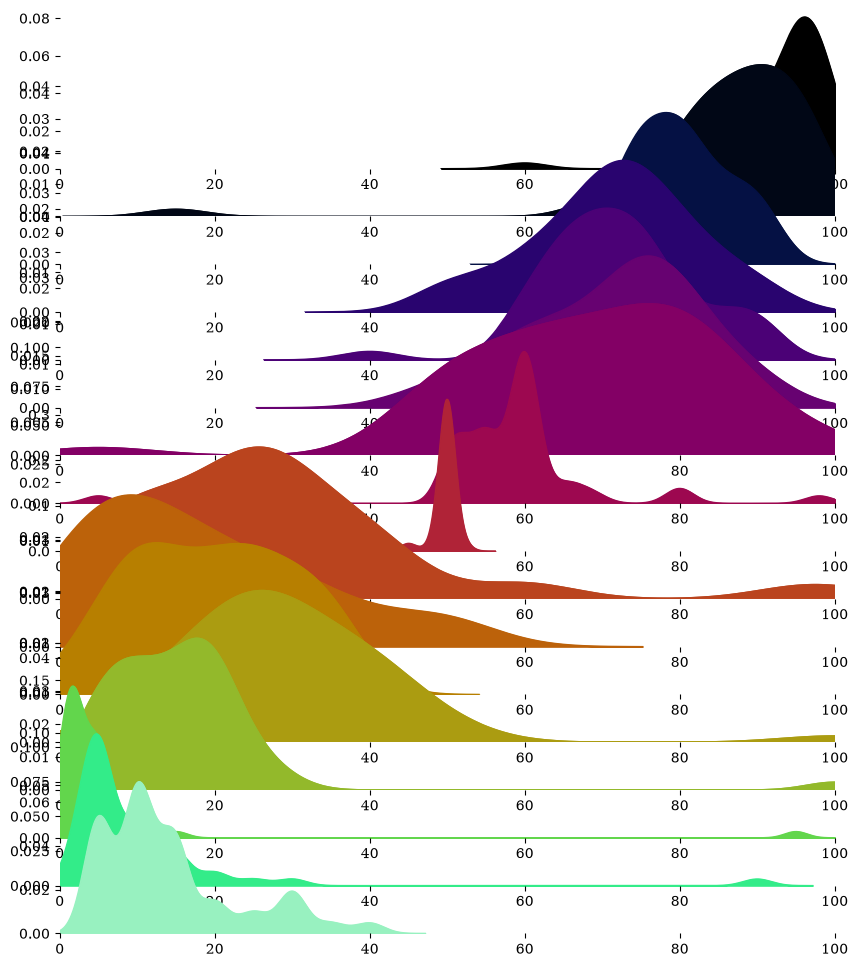

In [14]:
phrases = data.columns.values

gs = (gridspec.GridSpec(len(phrases),1))

fig = plt.figure(figsize=(10,12))

i = 0

#creating empty list
ax_objs = []

for phrase in phrases:
    # creating new axes object and appending to ax_objs
    ax_objs.append(fig.add_subplot(gs[i:i+1, 0:]))

    # Estimating the KDE
    counts = data[phrase].values
    kde_counts_x, kde_counts_y = FFTKDE(kernel='gaussian', bw='silverman').fit(counts).evaluate()


    # plotting
    ax_objs[-1].plot(kde_counts_x, kde_counts_y, color=colors[i],lw=1)
    ax_objs[-1].fill_between(kde_counts_x, kde_counts_y,color=colors[i],label=phrase)

    # Aesthetics
    ax_objs[-1].set_xlim(0,100)
    ax_objs[-1].set_ylim(0)

    # Spines and making them invisible 
    spines = ["top","right","left","bottom"]
    for s in spines:
        ax_objs[-1].spines[s].set_visible(False)

    # make background transparent
    rect = ax_objs[-1].patch
    rect.set_alpha(0)

    # Going to the next axes
    i += 1

# Reducing the horizontal space between axes (negative value makes them overlap)
gs.update(hspace=-0.7)

### Step 5: aesthetics
Now we can work on the aesthetics a bit:
- removing the x-axis ticks in all but the last axes
- removing all y-axis ticks
- adding a representative label for each distribution
- rescaling the heights to they don't overshadow each other too much

/home/arash/Dropbox/DataViz_2026/S3011_repo/.venv/lib/python3.14/site-packages/KDEpy/bw_selection.py:285: UserWarning: Silverman's rule failed. Too many idential values. Setting bw = 1.0321341385332972
  warnings.warn(


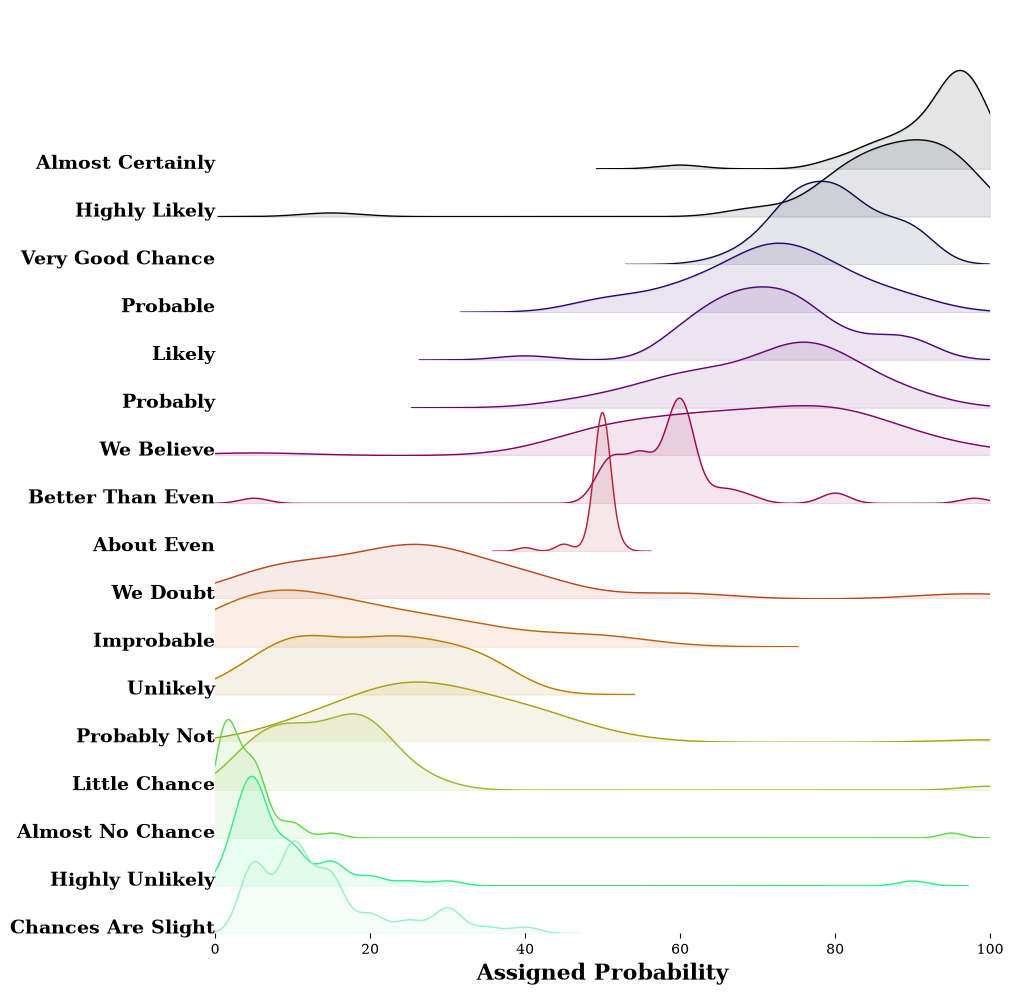

In [15]:
phrases = data.columns.values

gs = (gridspec.GridSpec(len(phrases),1))

fig = plt.figure(figsize=(10,12))

i = 0

#creating empty list
ax_objs = []

for phrase in phrases:
    # creating new axes object and appending to ax_objs
    ax_objs.append(fig.add_subplot(gs[i:i+1, 0:]))

    # Estimating the KDE
    counts = data[phrase].values
    kde_counts_x, kde_counts_y = FFTKDE(kernel='gaussian', bw='silverman').fit(counts).evaluate()


    # plotting
    ax_objs[-1].plot(kde_counts_x, kde_counts_y, color=colors[i],lw=1)
    ax_objs[-1].fill_between(kde_counts_x, kde_counts_y,color=colors[i],label=phrase,alpha=0.1)

    # Aesthetics
    ax_objs[-1].set_xlim(0,100)
    ax_objs[-1].set_ylim(0,max(kde_counts_y)+0.05)

    # Spines and making them invisible 
    spines = ["top","right","left","bottom"]
    for s in spines:
        ax_objs[-1].spines[s].set_visible(False)
    
    # make background transparent
    rect = ax_objs[-1].patch
    rect.set_alpha(0)

    # Ticks!
    ax_objs[-1].set_yticks([])
 
    if i == len(phrases)-1:
        ax_objs[-1].set_xlabel("Assigned Probability", fontsize=16,fontweight="bold")
    else:
       ax_objs[-1].set_xticks([])
 

    # Label
    ax_objs[-1].text(-0.02,0,phrase,fontweight="bold",fontsize=14,ha="right")

    
    # Going to the next axes
    i += 1

# Reducing the horizontal space between axes (negative value makes them overlap)
gs.update(hspace=-0.7)